In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python executable:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("All required libraries imported successfully!")

Python executable: c:\SahayakAi\backend\venv\Scripts\python.exe
Pandas: 3.0.5
NumPy: 2.5.2
All required libraries imported successfully!


In [3]:
from pathlib import Path

# Find the SahayakAI project root automatically
current_path = Path.cwd()
PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "ml" / "data").exists():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    PROJECT_ROOT = Path(r"C:\SahayakAi")

ML_DIR = PROJECT_ROOT / "ml"
RAW_DIR = ML_DIR / "data" / "raw"
PROCESSED_DIR = ML_DIR / "data" / "processed"
EVALUATION_DIR = ML_DIR / "evaluation"

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())
print("Processed data folder exists:", PROCESSED_DIR.exists())

Project root: c:\SahayakAi
Raw data folder exists: True
Processed data folder exists: True


In [4]:
files_to_check = [
    RAW_DIR / "access_risk_dataset.csv",
    RAW_DIR / "government_schemes.csv",
    PROCESSED_DIR / "government_schemes_clean.csv",
    PROCESSED_DIR / "X_train.csv",
    PROCESSED_DIR / "X_test.csv",
    PROCESSED_DIR / "y_train.csv",
    PROCESSED_DIR / "y_test.csv"
]

file_report = []

for file_path in files_to_check:
    file_report.append({
        "File": str(file_path.relative_to(PROJECT_ROOT)),
        "Exists": file_path.exists(),
        "Size (MB)": round(file_path.stat().st_size / (1024 * 1024), 3)
        if file_path.exists() else None
    })

display(pd.DataFrame(file_report))

,File,Exists,Size (MB)
0,ml\data\raw\access_risk_dataset.csv,True,0.077
1,ml\data\raw\government_schemes.csv,True,12.260
2,ml\data\processed\government_schemes_clean.csv,True,20.656
3,ml\data\processed\X_train.csv,True,0.168
4,ml\data\processed\X_test.csv,True,0.042
5,ml\data\processed\y_train.csv,True,0.005
6,ml\data\processed\y_test.csv,True,0.001


In [5]:
def load_dataset(file_path):
    if not file_path.exists():
        print(f"Not found: {file_path}")
        return None

    try:
        df = pd.read_csv(file_path, low_memory=False)
        print(
            f"Loaded {file_path.name}: "
            f"{df.shape[0]} rows × {df.shape[1]} columns"
        )
        return df

    except Exception as error:
        print(f"Could not load {file_path.name}: {error}")
        return None


access_df = load_dataset(
    RAW_DIR / "access_risk_dataset.csv"
)

schemes_raw_df = load_dataset(
    RAW_DIR / "government_schemes.csv"
)

schemes_clean_df = load_dataset(
    PROCESSED_DIR / "government_schemes_clean.csv"
)

X_train = load_dataset(PROCESSED_DIR / "X_train.csv")
X_test = load_dataset(PROCESSED_DIR / "X_test.csv")
y_train = load_dataset(PROCESSED_DIR / "y_train.csv")
y_test = load_dataset(PROCESSED_DIR / "y_test.csv")

Loaded access_risk_dataset.csv: 1000 rows × 14 columns
Loaded government_schemes.csv: 3400 rows × 11 columns
Loaded government_schemes_clean.csv: 3397 rows × 11 columns
Loaded X_train.csv: 800 rows × 31 columns
Loaded X_test.csv: 200 rows × 31 columns
Loaded y_train.csv: 800 rows × 1 columns
Loaded y_test.csv: 200 rows × 1 columns


In [6]:
if access_df is not None:
    print("Dataset shape:", access_df.shape)

    print("\nColumn names:")
    print(access_df.columns.tolist())

    print("\nFirst five records:")
    display(access_df.head())

    print("\nData types:")
    display(access_df.dtypes.to_frame("Data Type"))

    print("\nNumerical summary:")
    display(access_df.describe(include=[np.number]).T)

    print("\nDataset information:")
    access_df.info()

else:
    print("Access-risk dataset not found. Check the path in Cell 2.")

Dataset shape: (1000, 14)

Column names:
['age', 'annual_income', 'occupation', 'state', 'rural_or_urban', 'digital_literacy', 'internet_access', 'documents_complete', 'scheme_awareness', 'distance_to_service_center', 'application_complexity', 'previous_application_failure', 'access_risk', 'primary_barrier']

First five records:


,age,annual_income,occupation,state,rural_or_urban,digital_literacy,internet_access,documents_complete,scheme_awareness,distance_to_service_center,application_complexity,previous_application_failure,access_risk,primary_barrier
0,56,135186,Self Employed,Madhya Pradesh,Rural,4,Yes,Yes,4,3,3,No,Low,Documentation
1,69,326818,Daily Wage Worker,Rajasthan,Urban,1,No,No,5,35,5,Yes,High,Digital Access
2,46,196926,Farmer,West Bengal,Rural,1,No,Yes,4,33,5,No,High,Digital Access
3,32,76271,Homemaker,West Bengal,Urban,2,No,No,3,21,2,No,Medium,Digital Access
4,60,365832,Daily Wage Worker,Rajasthan,Urban,5,Yes,Yes,5,31,2,Yes,Medium,Distance



Data types:


,Data Type
age,int64
annual_income,int64
occupation,str
state,str
rural_or_urban,str
digital_literacy,int64
internet_access,str
documents_complete,str
scheme_awareness,int64
distance_to_service_center,int64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
age,1000.0,43.819,14.991030,18.0,31.00,44.0,56.0,69.0
annual_income,1000.0,260541.255,136557.551556,30126.0,143513.25,257620.0,379652.5,499209.0
digital_literacy,1000.0,3.052,1.399019,1.0,2.00,3.0,4.0,5.0
scheme_awareness,1000.0,2.927,1.433082,1.0,2.00,3.0,4.0,5.0
distance_to_service_center,1000.0,25.103,14.317031,1.0,13.00,25.0,37.0,50.0
application_complexity,1000.0,3.091,1.417296,1.0,2.00,3.0,4.0,5.0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   age                           1000 non-null   int64
 1   annual_income                 1000 non-null   int64
 2   occupation                    1000 non-null   str  
 3   state                         1000 non-null   str  
 4   rural_or_urban                1000 non-null   str  
 5   digital_literacy              1000 non-null   int64
 6   internet_access               1000 non-null   str  
 7   documents_complete            1000 non-null   str  
 8   scheme_awareness              1000 non-null   int64
 9   distance_to_service_center    1000 non-null   int64
 10  application_complexity        1000 non-null   int64
 11  previous_application_failure  1000 non-null   str  
 12  access_risk                   1000 non-null   str  
 13  primary_barrier        

In [7]:
if access_df is not None:
    missing_report = pd.DataFrame({
        "Data Type": access_df.dtypes.astype(str),
        "Missing Values": access_df.isnull().sum(),
        "Missing Percentage": (
            access_df.isnull().mean() * 100
        ).round(2),
        "Unique Values": access_df.nunique(dropna=True)
    })

    print("Total rows:", len(access_df))
    print("Duplicate rows:", access_df.duplicated().sum())
    print("Total missing cells:", access_df.isnull().sum().sum())

    display(
        missing_report.sort_values(
            "Missing Percentage",
            ascending=False
        )
    )

Total rows: 1000
Duplicate rows: 0
Total missing cells: 0


,Data Type,Missing Values,Missing Percentage,Unique Values
age,int64,0,0.0,52
annual_income,int64,0,0.0,1000
occupation,str,0,0.0,6
state,str,0,0.0,6
rural_or_urban,str,0,0.0,2
digital_literacy,int64,0,0.0,5
internet_access,str,0,0.0,2
documents_complete,str,0,0.0,2
scheme_awareness,int64,0,0.0,5
distance_to_service_center,int64,0,0.0,50


In [8]:
if access_df is not None:
    possible_target_columns = [
        col for col in access_df.columns
        if any(
            word in col.lower()
            for word in ["risk", "target", "label", "class", "barrier", "access"]
        )
    ]

    print("Potential target/risk columns:")
    print(possible_target_columns)

    categorical_columns = [
        col for col in access_df.columns
        if (
            pd.api.types.is_object_dtype(access_df[col])
            or isinstance(access_df[col].dtype, pd.CategoricalDtype)
            or pd.api.types.is_bool_dtype(access_df[col])
        )
        and access_df[col].nunique(dropna=True) <= 30
    ]

    print("\nCategorical columns:")
    print(categorical_columns)

    for col in categorical_columns:
        print(f"\nDistribution of: {col}")
        display(
            access_df[col]
            .value_counts(dropna=False)
            .head(20)
            .to_frame("Count")
        )

Potential target/risk columns:
['internet_access', 'access_risk', 'primary_barrier']

Categorical columns:
[]


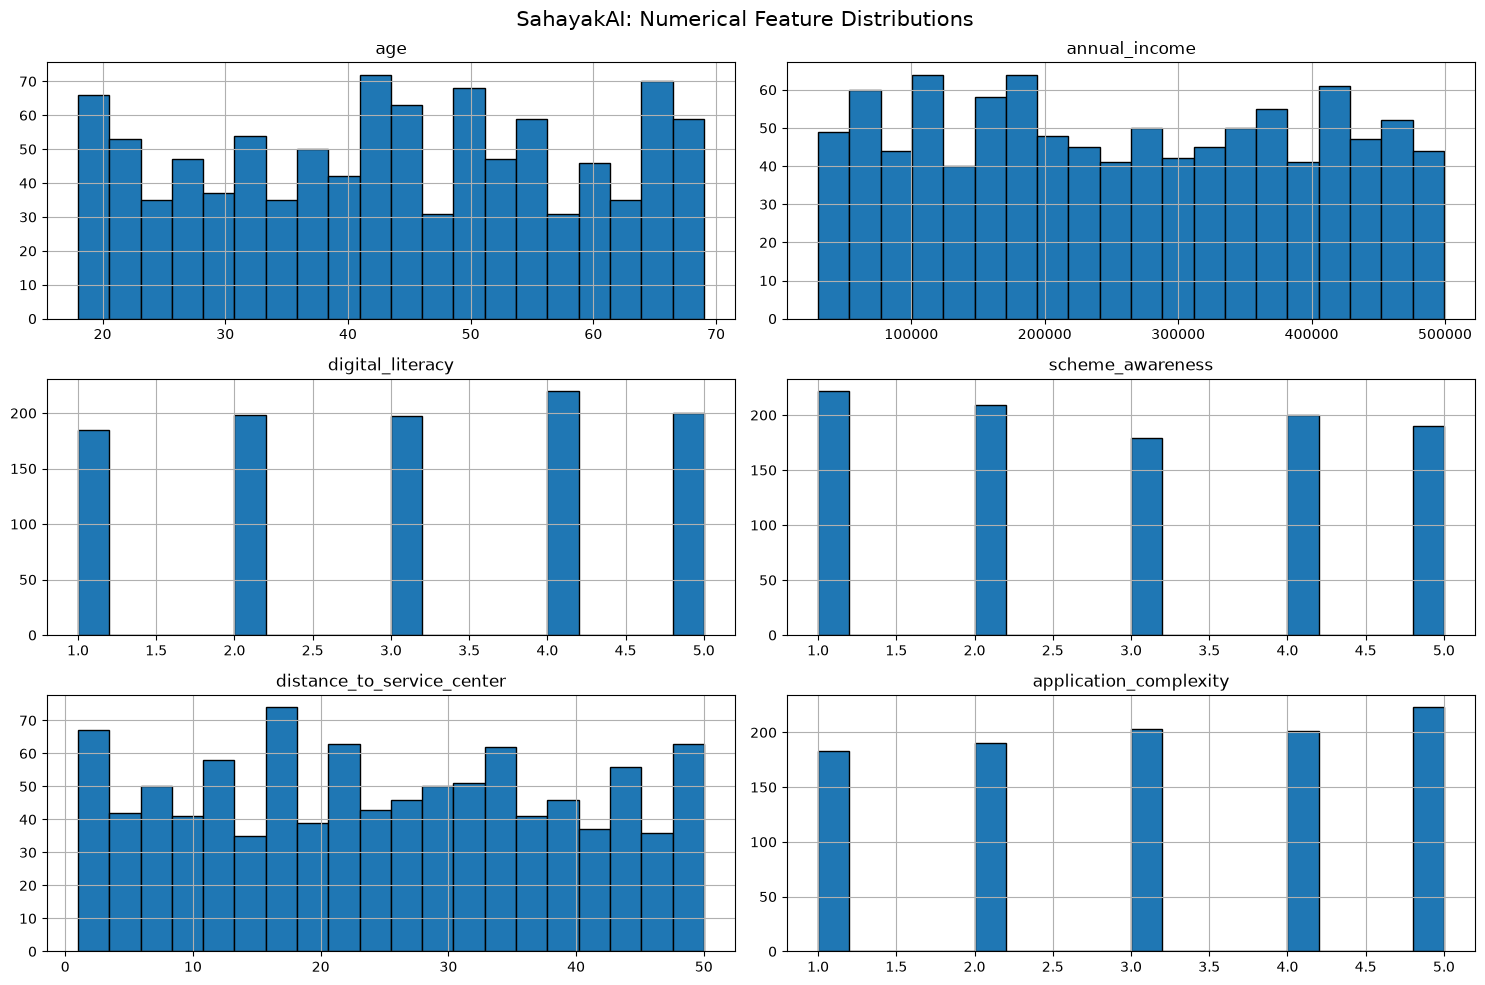

In [9]:
if access_df is not None:
    numerical_columns = access_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    if numerical_columns:
        access_df[numerical_columns].hist(
            figsize=(15, 10),
            bins=20,
            edgecolor="black"
        )

        plt.suptitle(
            "SahayakAI: Numerical Feature Distributions",
            fontsize=15
        )

        plt.tight_layout()
        plt.show()
    else:
        print("No numerical columns found.")

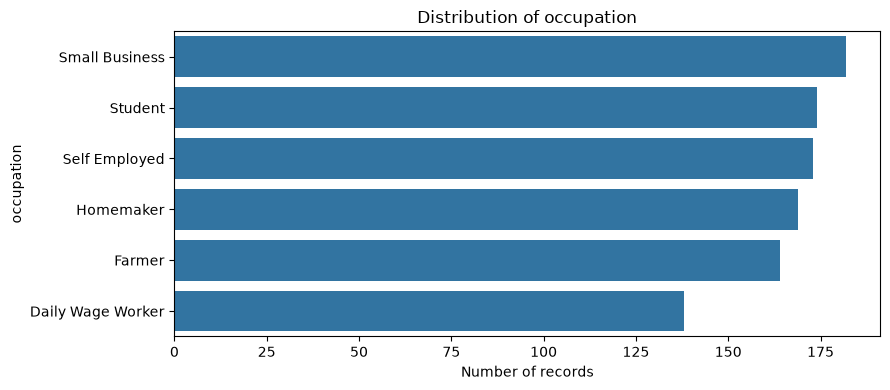

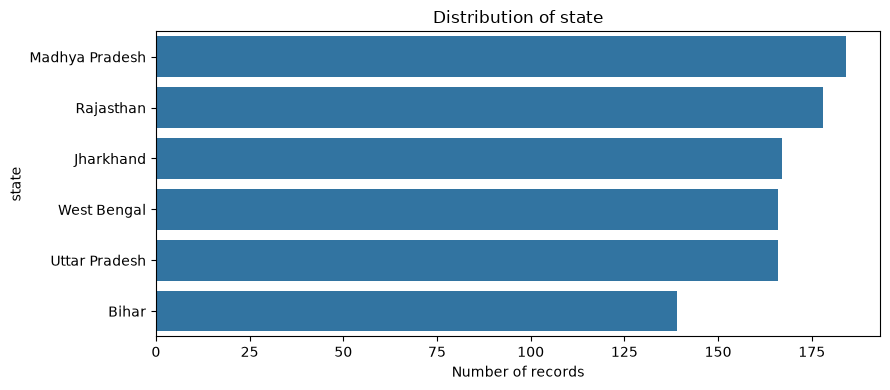

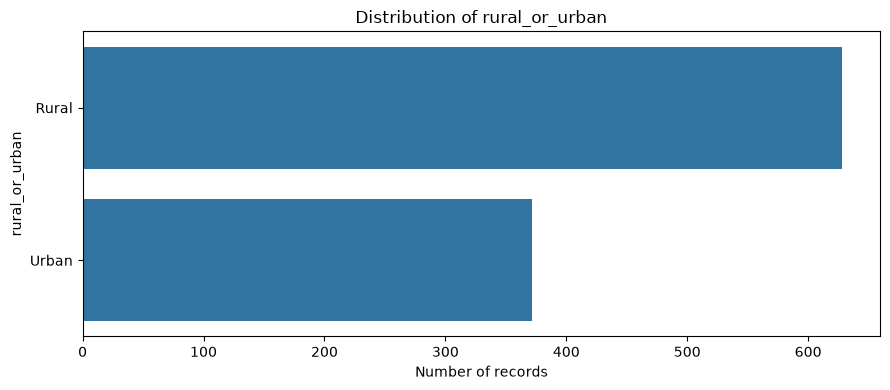

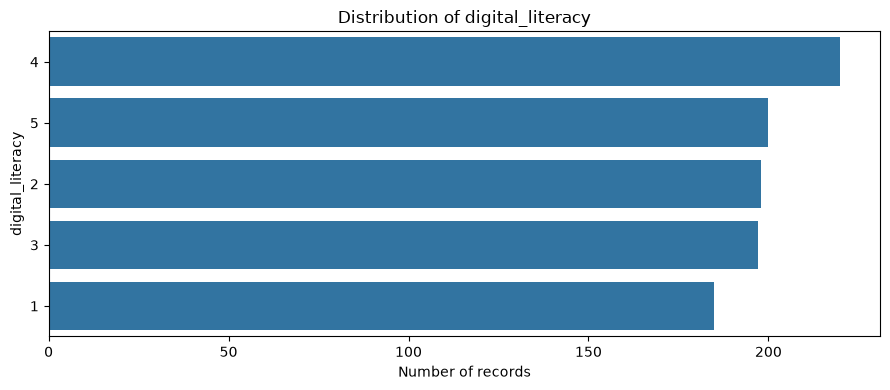

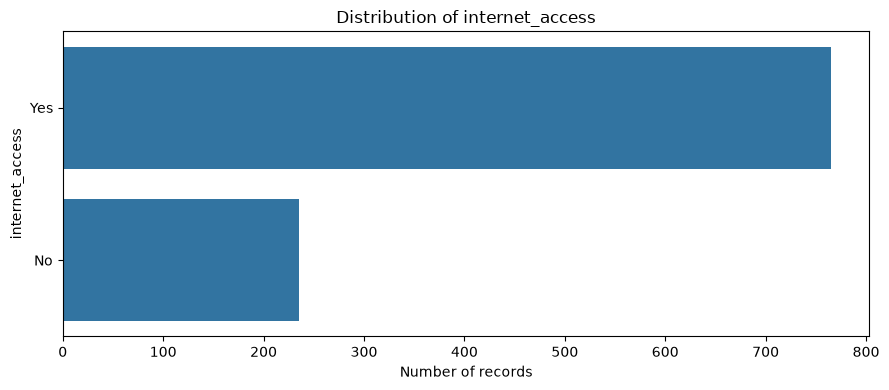

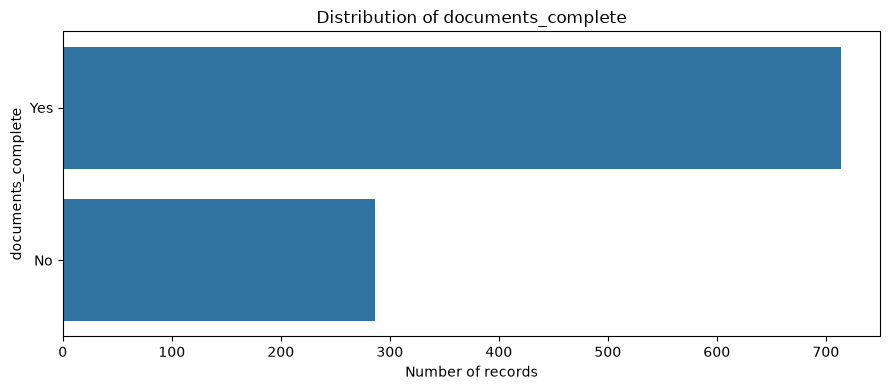

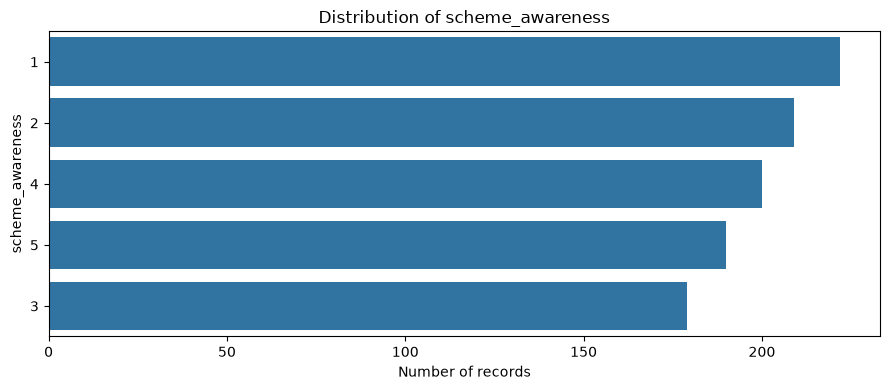

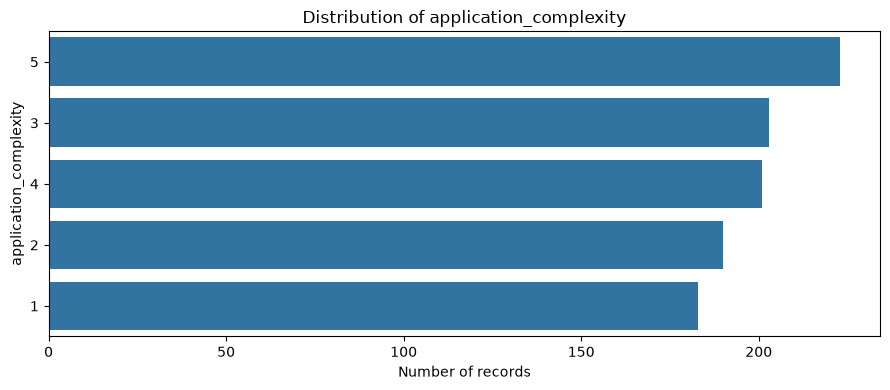

In [10]:
if access_df is not None:
    categorical_columns = [
        col for col in access_df.columns
        if access_df[col].nunique(dropna=True) <= 20
    ]

    for col in categorical_columns[:8]:
        counts = (
            access_df[col]
            .astype("string")
            .fillna("<missing>")
            .value_counts()
            .head(15)
        )

        plt.figure(figsize=(9, 4))
        sns.barplot(x=counts.values, y=counts.index)

        plt.title(f"Distribution of {col}")
        plt.xlabel("Number of records")
        plt.ylabel(col)

        plt.tight_layout()
        plt.show()

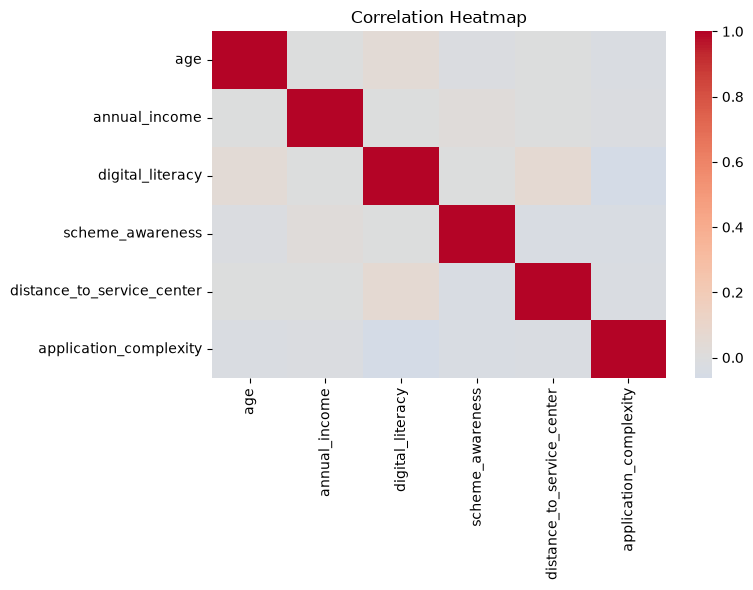

In [11]:
if access_df is not None:
    numerical_df = access_df.select_dtypes(
        include=np.number
    )

    if numerical_df.shape[1] >= 2:
        # Limit to 30 columns for readability
        numerical_df = numerical_df.iloc[:, :30]
        correlation_matrix = numerical_df.corr()

        plt.figure(
            figsize=(
                max(8, len(correlation_matrix.columns) * 0.6),
                max(6, len(correlation_matrix.columns) * 0.5)
            )
        )

        sns.heatmap(
            correlation_matrix,
            cmap="coolwarm",
            center=0,
            annot=False
        )

        plt.title("Correlation Heatmap")
        plt.tight_layout()
        plt.show()
    else:
        print("At least two numerical columns are required.")

In [12]:
def explore_schemes(df, dataset_name):
    if df is None:
        print(f"{dataset_name} is unavailable.")
        return

    print(f"\n{dataset_name}")
    print("=" * len(dataset_name))

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Duplicate rows:", df.duplicated().sum())
    print("Total missing cells:", df.isnull().sum().sum())

    print("\nFirst five records:")
    display(df.head())

    report = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Missing Values": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().mean() * 100
        ).round(2),
        "Unique Values": df.nunique(dropna=True)
    })

    display(
        report.sort_values(
            "Missing Percentage",
            ascending=False
        )
    )


explore_schemes(
    schemes_raw_df,
    "Raw Government Schemes Dataset"
)

explore_schemes(
    schemes_clean_df,
    "Processed Government Schemes Dataset"
)


Raw Government Schemes Dataset
Shape: (3400, 11)
Columns: ['scheme_name', 'slug', 'details', 'benefits', 'eligibility', 'application', 'documents', 'level', 'schemeCategory', 'Unnamed: 9', 'tags']
Duplicate rows: 3
Total missing cells: 3442

First five records:


,scheme_name,slug,details,benefits,eligibility,application,documents,level,schemeCategory,Unnamed: 9,tags
0,"""Immediate Relief Assistance"" under ""Welfare a...",ira-wrflsncs,"The scheme ""Immediate Relief Assistance"" is a ...","₹ 1,00,000, in two installments of ₹ 50,000 ea...",The applicant should be the family (legal heir...,Step 1: The interested applicant should visit ...,Photograph of the Family (Legal Heir) of the M...,State,"Agriculture,Rural & Environment, Social welfar...",NaN,"Missing, Fisherman, Relief, Financial Assistan..."
1,AICTE SHORT TERM TRAINING PROGRAMME-SFURTI SCHEME,astpss,"Short Term Training Programme-SFURTI Program, ...","Financial Assistance : Limit of funding ₹ 4,00...",The institution should be AICTE approved.,Registration of New Institute: Step 01: Visit ...,Feedback Form Copy of Proceedings Completion R...,Central,Education & Learning,NaN,"Trainings, Financial Assistance, AICTE"
2,Burial and Ex-gratia Payment Scheme in Case of...,baepsicodouldwact,"Launched in 2014, the "" Burial and Ex-gratia P...","Funeral Assistance: ₹3,000 payable in case of ...",The deceased construction worker should have b...,Step 1: The interested applicant should visit ...,Aadhaar Card of the applicant (nominee/Legal h...,State,Social welfare & Empowerment,NaN,"Building Worker, Construction Workers, Unregis..."
3,Consortia & Tender Marketing Scheme,ctms,Promotion of the product of Micro and Small En...,Enlistment of the Unit for participating in Go...,Micro & Small Enterprises registered with NSIC...,"Step 01: The application form, in the prescrib...",A passport size photograph of each of the Prop...,Central,Business & Entrepreneurship,NaN,"Goods And Services Marketing, Turnkey Projects..."
4,Garuda Scheme for Funeral Expense,gsfe,Andhra Pradesh Brahmin Welfare Corporation (AB...,"Financial Assistance of ₹10,000/- for funeral ...",The applicant should be a close relative of th...,Registration and apply Step 01: Applicants hav...,Passport-size Photograph of the Applicant Aadh...,State,Social welfare & Empowerment,NaN,"Social Welfare, Financial Assistance, Deceased..."


,Data Type,Missing Values,Missing Percentage,Unique Values
Unnamed: 9,float64,3400,100.00,0
tags,str,29,0.85,3271
documents,str,11,0.32,3052
application,str,2,0.06,2510
details,str,0,0.00,3382
scheme_name,str,0,0.00,3397
slug,str,0,0.00,3397
benefits,str,0,0.00,3304
eligibility,str,0,0.00,3274
schemeCategory,str,0,0.00,210



Processed Government Schemes Dataset
Shape: (3397, 11)
Columns: ['scheme_name', 'slug', 'details', 'benefits', 'eligibility', 'application', 'documents', 'level', 'schemeCategory', 'tags', 'search_text']
Duplicate rows: 0
Total missing cells: 42

First five records:


,scheme_name,slug,details,benefits,eligibility,application,documents,level,schemeCategory,tags,search_text
0,"""Immediate Relief Assistance"" under ""Welfare a...",ira-wrflsncs,"The scheme ""Immediate Relief Assistance"" is a ...","₹ 1,00,000, in two installments of ₹ 50,000 ea...",The applicant should be the family (legal heir...,Step 1: The interested applicant should visit ...,Photograph of the Family (Legal Heir) of the M...,State,"Agriculture,Rural & Environment, Social welfar...","Missing, Fisherman, Relief, Financial Assistan...","""Immediate Relief Assistance"" under ""Welfare a..."
1,AICTE SHORT TERM TRAINING PROGRAMME-SFURTI SCHEME,astpss,"Short Term Training Programme-SFURTI Program, ...","Financial Assistance : Limit of funding ₹ 4,00...",The institution should be AICTE approved.,Registration of New Institute: Step 01: Visit ...,Feedback Form Copy of Proceedings Completion R...,Central,Education & Learning,"Trainings, Financial Assistance, AICTE",AICTE SHORT TERM TRAINING PROGRAMME-SFURTI SCH...
2,Burial and Ex-gratia Payment Scheme in Case of...,baepsicodouldwact,"Launched in 2014, the "" Burial and Ex-gratia P...","Funeral Assistance: ₹3,000 payable in case of ...",The deceased construction worker should have b...,Step 1: The interested applicant should visit ...,Aadhaar Card of the applicant (nominee/Legal h...,State,Social welfare & Empowerment,"Building Worker, Construction Workers, Unregis...",Burial and Ex-gratia Payment Scheme in Case of...
3,Consortia & Tender Marketing Scheme,ctms,Promotion of the product of Micro and Small En...,Enlistment of the Unit for participating in Go...,Micro & Small Enterprises registered with NSIC...,"Step 01: The application form, in the prescrib...",A passport size photograph of each of the Prop...,Central,Business & Entrepreneurship,"Goods And Services Marketing, Turnkey Projects...",Consortia & Tender Marketing Scheme Promotion ...
4,Garuda Scheme for Funeral Expense,gsfe,Andhra Pradesh Brahmin Welfare Corporation (AB...,"Financial Assistance of ₹10,000/- for funeral ...",The applicant should be a close relative of th...,Registration and apply Step 01: Applicants hav...,Passport-size Photograph of the Applicant Aadh...,State,Social welfare & Empowerment,"Social Welfare, Financial Assistance, Deceased...",Garuda Scheme for Funeral Expense Andhra Prade...


,Data Type,Missing Values,Missing Percentage,Unique Values
tags,str,29,0.85,3271
documents,str,11,0.32,3052
application,str,2,0.06,2510
details,str,0,0.00,3382
slug,str,0,0.00,3397
scheme_name,str,0,0.00,3397
eligibility,str,0,0.00,3274
benefits,str,0,0.00,3304
level,str,0,0.00,2
schemeCategory,str,0,0.00,210


In [13]:
if schemes_clean_df is not None:
    relevant_columns = [
        col for col in schemes_clean_df.columns
        if any(
            word in col.lower()
            for word in [
                "name", "title", "scheme", "description",
                "benefit", "eligib", "ministry",
                "category", "state", "sector"
            ]
        )
    ]

    print("Potentially relevant columns:")
    print(relevant_columns)

    for col in relevant_columns[:8]:
        print(f"\nMost frequent values in: {col}")

        display(
            schemes_clean_df[col]
            .astype("string")
            .fillna("<missing>")
            .value_counts()
            .head(10)
            .to_frame("Count")
        )
else:
    print("Processed schemes dataset is unavailable.")

Potentially relevant columns:
['scheme_name', 'benefits', 'eligibility', 'schemeCategory']

Most frequent values in: scheme_name


,Count
scheme_name,
"""Immediate Relief Assistance"" under ""Welfare and Relief for Fishermen During Lean Seasons and Natural Calamities Scheme""",1
AICTE SHORT TERM TRAINING PROGRAMME-SFURTI SCHEME,1
Burial and Ex-gratia Payment Scheme in Case of Death of Unregistered Laborer During Work at Construction Site,1
Consortia & Tender Marketing Scheme,1
Garuda Scheme for Funeral Expense,1
Incentive For The Intra Caste Marriage within Scheduled Tribe Community,1
Incentive Scheme for MSMEs in Powerloom Sector: State Capital Investment Subsidy,1
Indira Mahila Shakti Udyam Protsahan Yojana,1
Mukhyamantri Shramik Aujaar Sahayata Yojana,1



Most frequent values in: benefits


,Count
benefits,
"Cash Award of ₹2,00,000/- and a Citation.",6
"Pension: ₹1,000/- per month. Free Clothes during Pongal and Deepavali: One free dhoti to a male pensioner. One free saree to a female pensioner. Free Rice in Anganwadi Centres: 2kg/month to those who are taking nutritious meal. 4kg/month to those who are not taking nutritious meal.",6
"Decoration The Awardee is given a Citation, Memento, and a Cash award of ₹ 2,50,000/-. ﻿ No. of Awardees The total number of Awardees is 15 (Fifteen). ﻿ Presentation of Award (Ceremony Details) The Award shall be presented in New Delhi at a special ceremony/function to be held on the occasion of the International Day of Older Persons on the 1st of October every year. The Awards shall be presented by the President of India or the Prime Minister of India. The boarding and lodging expenses of the awardees including one companion for each awardee shall be borne by the Central Government. The to-and-fro travelling expenses and accommodation for up to one day prior to and after the date of the Samman ceremony (depending upon the actual arrival and departure dates) shall be arranged and the expenditure shall be reimbursed by the Central Government. The TA/ DA admissibility of the awardees and one companion shall be equivalent to that of the Joint Secretary to the Government of India.",5
"Amount : ₹ 1,500/- per month",4
"Pension: ₹1,000/- per month. Free Clothes during Pongal and Deepavali: One free saree. Free Rice in Anganwadi Centres: 2kg/month to those who are taking nutritious meals. 4kg/month to those who are not taking nutritious meals.",4
"Pension Amount: The scale of benefit under the pension will be notified by the Government of Andhra Pradesh. Mode of Disbursement: The Panchayat Secretary disburses the pension to the eligible citizens, in the presence of Sarpanch, Gram Panchayat Members and the Office Bearers of Village Organization. Time of Disbursement: The pension is disbursed on the first date of every month.",4
Pension Amount: The scale of benefit under the pension will be notified by the Government of Andhra Pradesh. Mode of Disbursement: The Bill Collector disburses the pension to the eligible individuals in the presence of Ward members and office bearers of DWCUA. Time of Disbursement: The pension is disbursed on the first date of every month.,4
"Substantial Financial Support: Receive up to ₹10,00,000/- for setting up a business (50% of the total financial assistance (up to ₹5,00,000/-) is provided as a non-repayable grant. The remaining 50% (up to ₹5,00,000/-) is offered as an interest-free loan, with a nominal 1% interest under specific sub-schemes.) Skill Development: Mandatory training sessions are provided to enhance entrepreneurial skills.",4
"Decoration The Awardee is given a Certificate and a Shield ﻿ Award Categories One Award for providing holistic comprehensive Rehabilitation Services. One Award for promoting and imparting Inclusive Education or educational institutions that are preparing children with disabilities for inclusive education for higher studies. ﻿ ﻿ Presentation of Award (Ceremony Details) 1. The ceremony of the National Awards is held at Vigyan Bhawan, New Delhi on 3rd December, every year which has been declared as the “International Day of Persons with Disabilities”. 2. The National Awards are presented through the Hon'ble President or Hon'ble Vice President of India. 2. The boarding and lodging expenses of the awardees and one escort shall be borne by the Department of Empowerment of Persons with Disabilities, Ministry of Social Justice and Empowerment. 3. To and fro travelling expenses and accommodation for up to one day prior to and after the day of the awards ceremony shall be arranged and the expenditure shall be reimbursed by the Department of Empowerment of Persons with Disabilities, Ministry of Social Justice and Empowerment. 4. The TA/DA admissibility of the awardees and their escorts shall be equivalent to a Class-I officer of the Cent


Most frequent values in: eligibility


,Count
eligibility,
The applicant should be a resident of Meghalaya. The applicant should be a bonafide farmer engaged in agriculture.,10
"Any individual or group of individuals with an innovative idea or concept, recommended by an approved Nodal Institution, is eligible. The scheme is open to startups in any sector or branch of science, technology, engineering, agriculture, healthcare, etc., making it sector-agnostic. Note: Startups availing benefits under the Student Startup and Innovation Policy (SSIP) are also eligible.",7
The applicant should be a permanent resident of Meghalaya. The applicant should be a bonafide farmer engaged in agriculture.,6
For Registration as a Building/ Construction Worker: The applicant should be a resident of U.T. Administration of Dadra and Nagar Haveli and Daman and Diu. The applicant should be a Building/ Construction Worker. The applicant should be between 18 and 60 years. The applicant should have engaged in any building or other construction work for at least 90 days in a given year. For the Application of the Welfare Scheme: The applicant should be a registered member under the Building and Other Construction Workers Welfare Board of U.T. Administration of Dadra and Nagar Haveli and Daman and Diu.,5
"The applicant should be a resident of Haryana. The applicant should belong to the Scheduled Caste Category. The applicant should belong to the Below Poverty Line (BPL) family. The applicant's annual family income should not exceed ₹1,80,000/- in both rural and urban areas. The applicant's annual family income should not exceed the BPL limit. The applicant's name should be included in the BPL Survey List. Note: The eligibility of the applicant is verified by the field staff before sponsoring the same to the bank for sanction.",5
"Should be a Private sector entity or Existing/ Operational industrial parks. Should have a minimum of 5 acres of legally owned land (by direct purchase or lease from the State Government). Special Purpose Vehicle (SPV) must be registered under Companies Act/ Societies Registration Act/Partnership Act/ LLP. Park area should be expanded up to minimum 5 acres in outlying districts and minimum 2 acres in Kolkata and Howrah. The individual units have complied with all the necessary clearances for land conversion, fire licence, environmental issues, building plan etc.",5
"The applicant must be between 18 and 60 years of age at the time of enrolment. The applicant must be an unorganized worker employed in the operation of commercial vehicles, such as cars, taxis, luxury taxis, light commercial vehicles, vans, auto-rickshaws, tempos, lorries, trucks, or buses. The applicant’s vehicle must be used for commercial purposes and not solely for personal or family use.",5
"The Scheme shall be generally applicable to all eligible tourism projects/units/expansion projects of existing units set up on or after the effective date (i.e. 22nd February, 2021) of this incentive scheme. Or, Eligible Hotel Units who started their commercial operation on or after 7th January, 2015 to 31st December, 2020 but could not apply under previous scheme 2015 due to absence of a Bar in the Hotel. The units may be in the private sector, co-operative sector, joint sector as also companies/undertakings owned or managed by the State Government. The project should be covered by a detailed feasibility report/project prepared for the purpose. The project should have been approved and sanctioned by a Central Financial Institution or Commercial Banks or State Financial Institutions. The unit should hold an Registration Certificate, Date of Commencement Certificate and Eligibility Certificate issued by the West Bengal Tourism Development Corporation Limited on satisfaction of arrangement.",4
The business/organization should be a Micro/ Small/ Medium Enterprise. The business/organization should belong to the manufacturing sector. The business/organization should have started production on or after 1st April 2019. T


Most frequent values in: schemeCategory


,Count
schemeCategory,
Social welfare & Empowerment,641
Education & Learning,557
"Agriculture,Rural & Environment",384
Business & Entrepreneurship,332
"Social welfare & Empowerment, Women and Child",149
Health & Wellness,100
Skills & Employment,94
"Education & Learning, Social welfare & Empowerment",75
"Banking,Financial Services and Insurance",58


In [14]:
datasets = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test
}

print("Dataset dimensions")
print("-" * 40)

for name, dataset in datasets.items():
    if dataset is None:
        print(f"{name}: unavailable")
    else:
        print(f"{name}: {dataset.shape}")


if X_train is not None and X_test is not None:
    print(
        "\nFeature counts match:",
        X_train.shape[1] == X_test.shape[1]
    )

if X_train is not None and y_train is not None:
    print(
        "Training row counts match:",
        len(X_train) == len(y_train)
    )

if X_test is not None and y_test is not None:
    print(
        "Test row counts match:",
        len(X_test) == len(y_test)
    )

Dataset dimensions
----------------------------------------
X_train: (800, 31)
X_test: (200, 31)
y_train: (800, 1)
y_test: (200, 1)

Feature counts match: True
Training row counts match: True
Test row counts match: True


In [15]:
if access_df is not None:
    column_report = pd.DataFrame({
        "Unique Values": access_df.nunique(dropna=True),
        "Unique Percentage": (
            access_df.nunique(dropna=True)
            / max(len(access_df), 1) * 100
        ).round(2)
    })

    column_report["Constant Column"] = (
        column_report["Unique Values"] <= 1
    )

    column_report["Potentially High Cardinality"] = (
        column_report["Unique Percentage"] >= 90
    )

    display(
        column_report.sort_values(
            "Unique Percentage",
            ascending=False
        )
    )

,Unique Values,Unique Percentage,Constant Column,Potentially High Cardinality
annual_income,1000,100.0,False,True
age,52,5.2,False,False
distance_to_service_center,50,5.0,False,False
occupation,6,0.6,False,False
state,6,0.6,False,False
digital_literacy,5,0.5,False,False
primary_barrier,5,0.5,False,False
scheme_awareness,5,0.5,False,False
application_complexity,5,0.5,False,False
access_risk,3,0.3,False,False


In [16]:
if access_df is not None:
    summary = {
        "Number of records": len(access_df),
        "Number of columns": len(access_df.columns),
        "Duplicate rows": int(access_df.duplicated().sum()),
        "Missing cells": int(access_df.isnull().sum().sum()),
        "Numerical columns": len(
            access_df.select_dtypes(include=np.number).columns
        ),
        "Categorical columns": len(
            access_df.select_dtypes(
                include=["object", "category", "bool"]
            ).columns
        )
    }

    display(
        pd.DataFrame(
            summary.items(),
            columns=["Metric", "Value"]
        )
    )
else:
    print("Cannot create summary because access-risk data is unavailable.")

C:\Users\Khushi\AppData\Local\Temp\ipykernel_18336\1652197831.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  access_df.select_dtypes(


,Metric,Value
0,Number of records,1000
1,Number of columns,14
2,Duplicate rows,0
3,Missing cells,0
4,Numerical columns,6
5,Categorical columns,8


# Findings and Validation Checklist

## Data exploration findings

Complete this section after running the notebook, using the actual outputs.

1. Access-risk dataset size:
2. Number of features:
3. Missing values:
4. Duplicate records:
5. Important feature distributions:
6. Potential data-quality issues:
7. Government schemes dataset size:
8. Dataset source and license status:

## Validation checklist

- [ ] Confirm the source and license of each dataset.
- [ ] Confirm how synthetic access-risk labels were generated.
- [ ] Inspect missing values, duplicates and invalid values.
- [ ] Verify the target label and feature definitions.
- [ ] Check for target leakage.
- [ ] Verify that training and test records are properly separated.
- [ ] Confirm preprocessing was fitted on training data only.
- [ ] Evaluate precision, recall, F1-score and confusion matrix.
- [ ] Compare the model with a baseline.
- [ ] Verify scheme details against official sources.
- [ ] Clearly document that synthetic-data results are experimental.